# 01: Prepare clips and generate weather variations

This notebook covers the batch side of the workflow:

1. **Ray Core**: tasks and actors, the building blocks of the generation pool.
2. **Ray Data**: turning raw TartanDrive 2.0 camera frames into model-ready clips and edge controls.
3. **Generation**: a pool of persistent GPU actors running NVIDIA Cosmos Transfer 2.5.
4. **Scaling**: the same 24 requests on 1, 2, 4 and 8 GPUs.

With `USE_GPUS = False` (the default) every cell runs on CPU and reads stored results from the data bundle. Set `USE_GPUS = True` to generate live.

In [1]:
# Setup
USE_GPUS = False   # False: stored results on CPU. True: generate live on GPUs (template image + weights).

import os, sys
sys.path.insert(0, os.getcwd())
import pandas as pd
import notebook_helpers as nh

pd.set_option("display.max_colwidth", 80)
nh.check_setup(USE_GPUS)

COSMOS_SHARED = /mnt/user_storage/cosmos-video-augmentation  (99 videos in the bundle)
Mode: stored results on CPU (set USE_GPUS = True to generate)


## 1. Ray Core in brief

A **task** is a function that runs somewhere on the cluster. An **actor** is a class instance that lives on one node and keeps its state between calls. The generation pool in this template is built from actors, because loading Cosmos Transfer 2.5 takes about a minute and should happen once per GPU, not once per clip.

In [2]:
import ray
from offroad_ray.ray_env import init_ray

init_ray()
print({k: v for k, v in ray.cluster_resources().items() if k in ("CPU", "GPU", "memory")})

{'CPU': 96.0, 'memory': 907097092924.0, 'GPU': 8.0}


In [3]:
from pathlib import Path

@ray.remote(num_cpus=1)
def probe_clip(path: str) -> dict:
    """A task: read the video header of one clip."""
    from offroad_ray.video_io import probe
    p = probe(path)
    return {"clip": Path(path).parent.name, "width": p["width"], "height": p["height"],
            "frames": p["frames"], "fps": round(p["fps"], 2)}

refs = [probe_clip.remote(str(nh.MEDIA / sid / "src.mp4")) for sid in nh.scenes()]   # runs in parallel
pd.DataFrame(ray.get(refs))

,clip,width,height,frames,fps
0,fb9d3bafac,1024,544,93,16.0
1,dd5a2ee56e,1024,544,93,16.0
2,5d20270fcc,1024,544,93,16.0
3,1b210bceff,1024,544,93,16.0
4,6e36465c49,1024,544,93,16.0
5,790e27532e,1024,544,93,16.0
6,9ab6805b7c,1024,544,93,16.0
7,833f53f9d2,1024,544,93,16.0
8,242efb7e7e,1024,544,93,16.0


In [4]:
@ray.remote(num_cpus=0.5)
class FrameReader:
    """An actor: state (here a call counter) persists between calls, as a loaded model does."""
    def __init__(self):
        self.calls = 0

    def first_frame_shape(self, path: str):
        import cv2
        self.calls += 1
        ok, frame = cv2.VideoCapture(path).read()
        return frame.shape, self.calls

reader = FrameReader.remote()
ray.get([reader.first_frame_shape.remote(str(nh.MEDIA / sid / "src.mp4")) for sid in list(nh.scenes())[:3]])

[((544, 1024, 3), 1), ((544, 1024, 3), 2), ((544, 1024, 3), 3)]

## 2. Prepare clips with Ray Data

TartanDrive 2.0 records the ATV's front camera at 10 Hz. Cosmos Transfer 2.5 expects 93 frames at 16 fps, plus a control video: here, the Canny edge map of every frame. The preparation pipeline decodes frames, checks timestamps, resamples by repeating the nearest frame, encodes the model input, verifies it by decoding it back and computes the edge control. Ray Data spreads this across CPUs with one clip per block.

```python
ds = (ray.data.from_items(runs)
      .flat_map(plan_clips)                          # choose clip windows per drive
      .repartition(target_num_rows_per_block=1)      # one clip per block
      .map(prepare_clip, num_cpus=2,                 # decode, resample, edges, verify
           compute=ray.data.TaskPoolStrategy(size=concurrency)))
ds.write_parquet(catalog_dir)
```

The cell below runs the pipeline live when the raw footage is present (`python scripts/setup_data.py --with-raw`, about 1.5 GB). Otherwise it shows the stored statistics from the original 27-clip run.

In [5]:
from offroad_ray.config import load_config

cfg = load_config("configs/quickstart.yaml")
if (cfg.paths.raw_dir / cfg.dataset.runs[0]).exists():
    from offroad_ray.preprocessing import run_prepare
    stats = run_prepare(cfg, concurrency=4)
else:
    print("Raw footage not downloaded: showing the stored preparation run.")
    stats = nh.read_json(nh.RESULTS / "dataset" / "prepare_main.json")
{k: stats[k] for k in ("ok", "rows", "wall_s", "cache_hits") if k in stats}

Raw footage not downloaded: showing the stored preparation run.


{'ok': 27, 'rows': 27, 'wall_s': 26.59, 'cache_hits': 18}

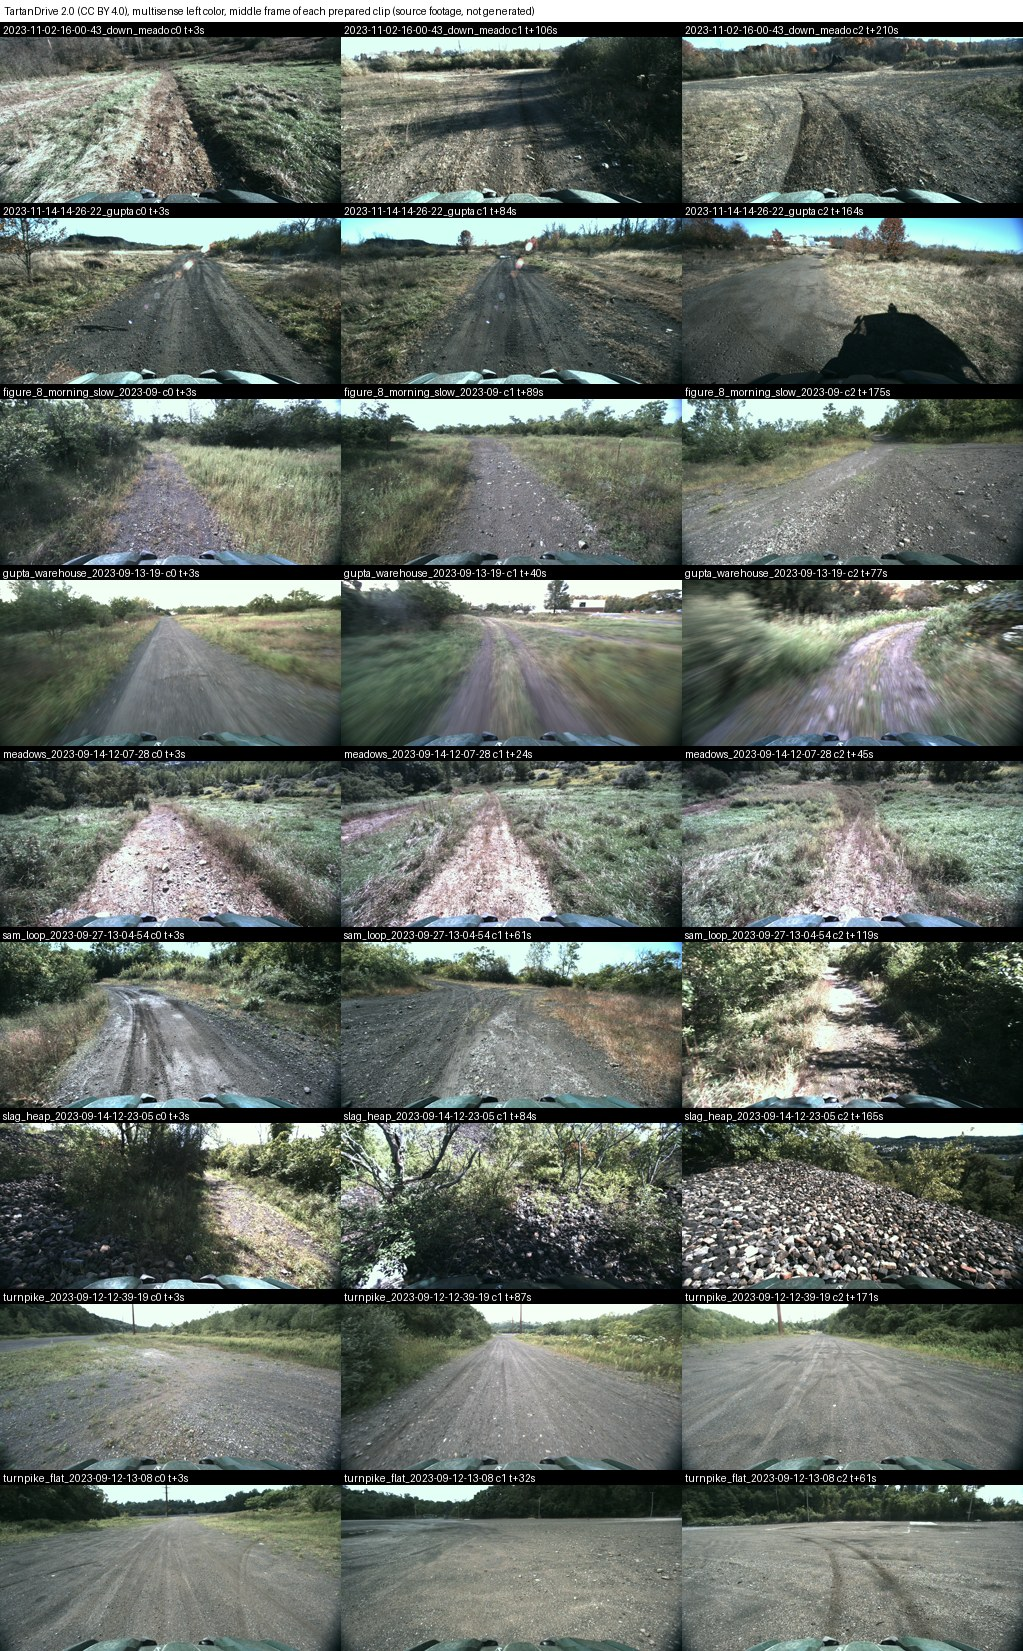

In [6]:
from IPython.display import Image
Image(str(nh.RESULTS / "dataset" / "contact_sheet.jpg"), width=900)

## 3. Generate with persistent GPU actors

Each actor owns one GPU and one long-lived child process running Cosmos Transfer 2.5 in its own Python environment, so its pinned PyTorch and CUDA stack never conflicts with the driver. The model loads once per actor and serves every request sent to that GPU.

A scheduler built on `ray.wait` keeps one request in flight per actor and dispatches the next one as soon as an actor is free. It retries infrastructure failures on a replacement actor, never retries a guardrail block, validates each output and writes a record per request, so an interrupted run resumes from the last completed request.

```python
while pending or in_flight:
    done, _ = ray.wait(list(in_flight), num_returns=1, timeout=5.0)
    for ref in done:
        i, req, t0 = in_flight.pop(ref)
        record(req, ray.get(ref))
        free.append(i)
    while free and pending:
        i, req = free.popleft(), pending.popleft()
        in_flight[actors[i].generate.remote(req)] = (i, req, time.time())
```

In [7]:
if USE_GPUS:
    from offroad_ray.cli import _catalog
    from offroad_ray.inference.scheduler import build_requests, run_pool
    ns = str(cfg.paths.runs_dir / cfg.name / "main")
    requests = build_requests(cfg, _catalog(cfg), ns)
    summary = run_pool(cfg, requests, ns, num_actors=cfg.scheduler.num_actors, resume=True)
    manifest = nh.read_jsonl(Path(ns) / "manifest.jsonl")
else:
    manifest = nh.read_jsonl(nh.RESULTS / "main" / "manifest.jsonl")   # 24 clips x 4 conditions x 3 seeds
    summary = nh.read_json(nh.RESULTS / "main" / "pool_summary.json")

print(f"{len(manifest)} requests, {summary['wall_s']:.0f} s wall on {summary['num_actors']} GPUs")
manifest["status"].value_counts()

288 requests, 3090 s wall on 8 GPUs


status
generated_unreviewed    288
Name: count, dtype: int64

The 4 denoising steps account for most of each request, so throughput scales with the number of GPUs working in parallel:

In [8]:
nh.stage_table(manifest)

,stage,median_s,share
0,"Denoising, 4 steps",63.57,79.1%
1,Video guardrail,5.03,6.3%
2,Decode and postprocessing,4.03,5.0%
3,Preprocessing,1.18,1.5%
4,Text guardrail,0.64,0.8%
5,Total per request,80.32,100%


One generated frame per condition, from the same real clip and edge map:

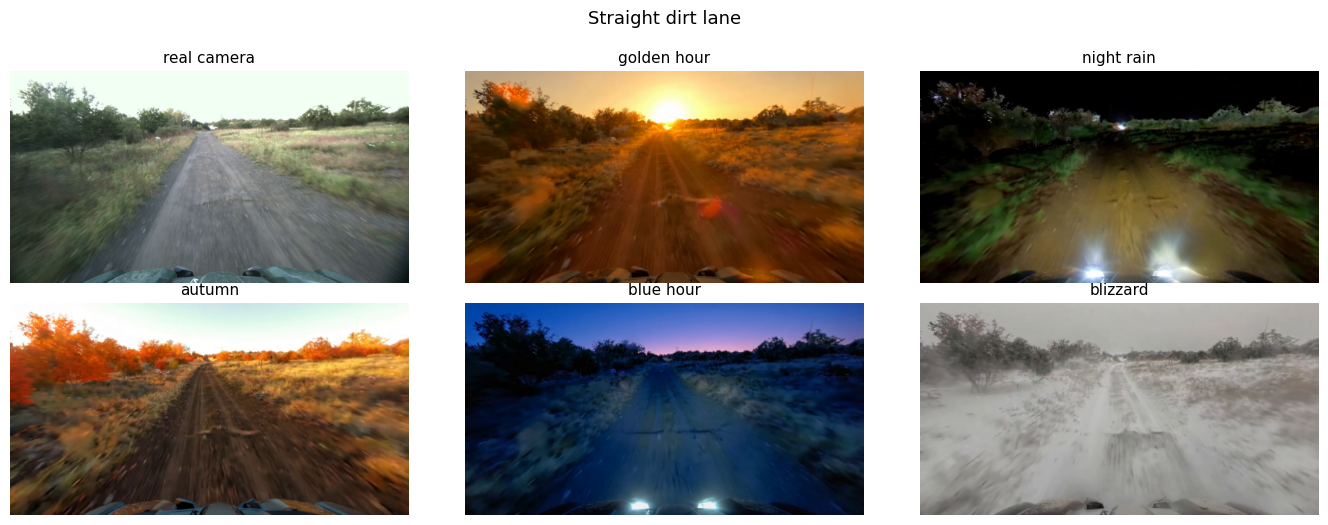

In [9]:
nh.show_conditions("5d20270fcc", ["golden_hour_glare", "night_rain", "autumn", "blue_hour_dusk", "blizzard_whiteout"])

Across the clip, the generated video follows the real vehicle motion frame by frame:

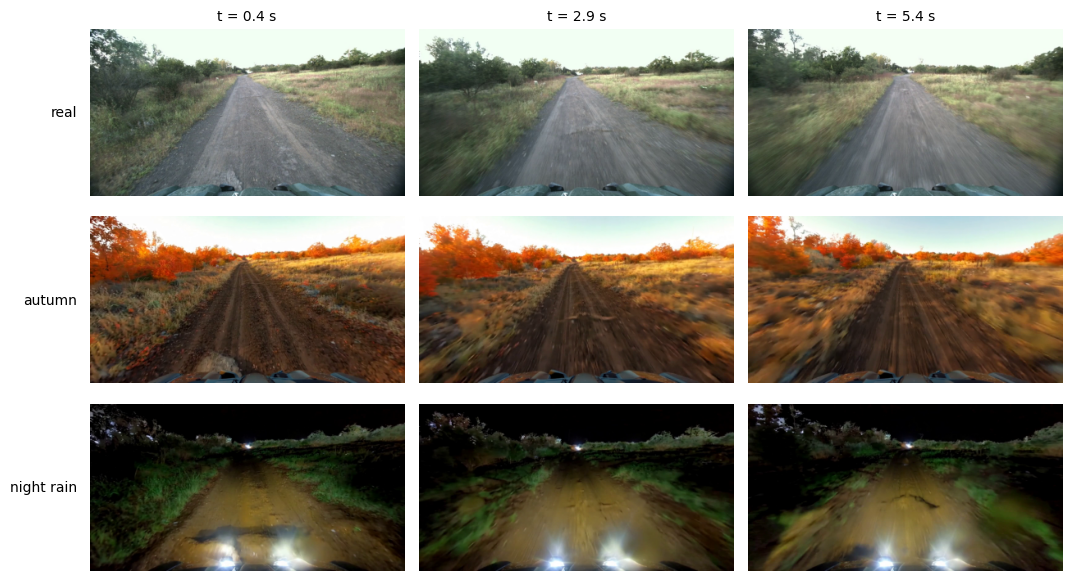

In [10]:
sid = "5d20270fcc"
nh.show_strip([nh.MEDIA / sid / "src.mp4", nh.MEDIA / sid / "autumn.mp4", nh.MEDIA / sid / "night_rain.mp4"],
              ["real", "autumn", "night rain"])

## 4. Scaling from 1 to 8 GPUs

The same 24 requests ran on 1, 2, 4 and 8 actors. The median request time stays flat, so actors do not slow each other down. End-to-end speedup is lower because every actor first loads the model (about 106 seconds), which only 3 requests per actor amortize in the 8-actor case.

In [11]:
scaling = nh.scaling_frame()
scaling

,num_actors,wall_s,speedup_gen,efficiency_gen,speedup_e2e,cold_start_s,median_request_s
0,1,2067.75,1.000,1.000,1.000,106.11,79.79
1,2,1107.90,1.960,0.980,1.866,106.52,80.19
2,4,624.94,3.750,0.937,3.309,105.20,80.26
3,8,398.39,6.976,0.872,5.190,108.04,80.27


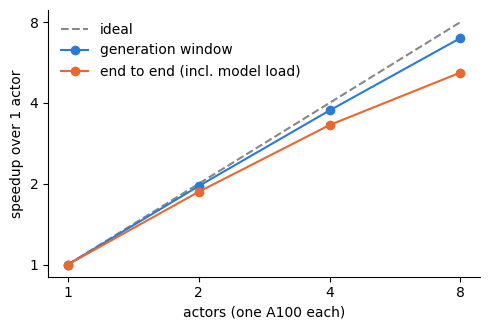

In [12]:
nh.plot_scaling(scaling)

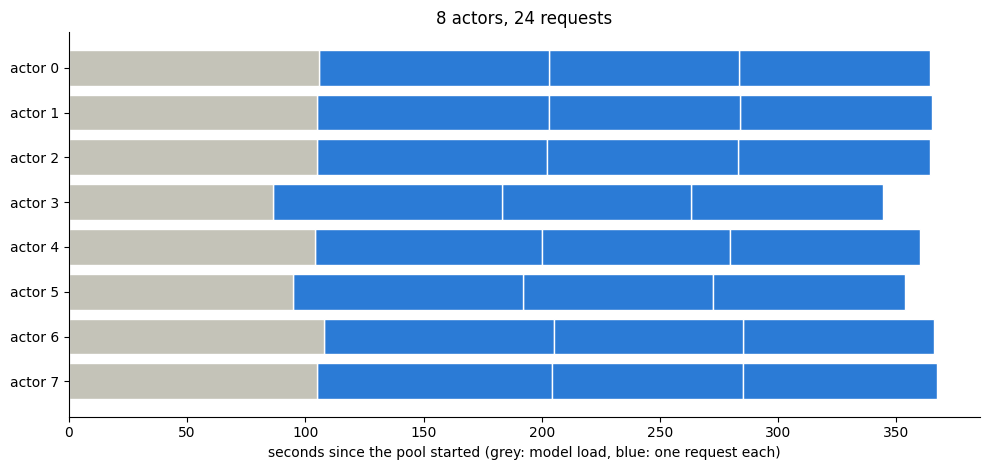

In [13]:
nh.plot_timeline("a8")

## Next

* [02_quality_and_review.ipynb](02_quality_and_review.ipynb) scores the outputs with a Ray Data pass on CPU.
* [03_serve.ipynb](03_serve.ipynb) puts the same actors behind an interactive Ray Serve application.